In [1]:
import numpy as np
import pandas as pd 

import matplotlib.pyplot as plt 
import seaborn as sns
import plotly.express as px 

In [2]:
df = pd.read_csv('WA_Telco-Customer-Churn.csv')

df.head() 

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
#finidng missing value
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
#blank space check
df['TotalCharges'].str.strip().eq('').sum()

np.int64(11)

In [7]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [8]:
#pd.to_numeric() → String থেকে Numeric-এ Convert করে।
#errors='coerce' → যেসব Value Convert করা সম্ভব নয়, সেগুলোকে NaN করে দেয়।

df['TotalCharges']=pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [9]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [10]:
df['TotalCharges'].describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

In [11]:
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [12]:
df.loc[
    df['TotalCharges'].isnull(),
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
] 

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [13]:
#missing valu glo 0 deya fill up
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [14]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [15]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [16]:
# Now duplicate Rows check
df.duplicated().sum()

np.int64(0)

In [17]:
df['customerID'].duplicated().sum()

np.int64(0)

In [18]:
# Numerical columns
df.select_dtypes(include=np.number).columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

In [19]:
# categorical columns
df.select_dtypes(include='str').columns

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')

In [20]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [21]:
df.describe(include='str')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


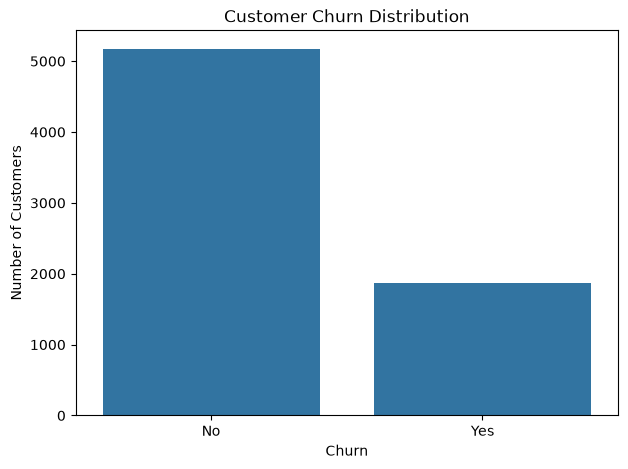

In [22]:
plt.figure(figsize=(7,5))
sns.countplot(data=df,x='Churn')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

In [23]:
# churn rate find out
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [24]:
pd.crosstab(
    df['Contract'], 
    df['Churn'], 
    normalize='index'
)*100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


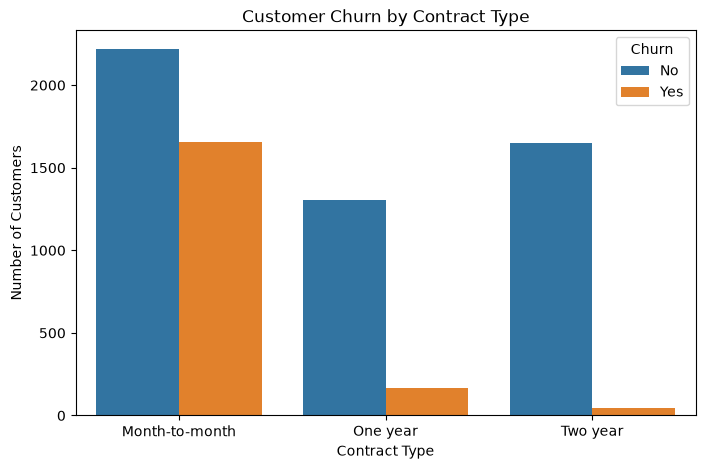

In [25]:
#using seaborn
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn'
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

In [26]:
pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


In [27]:
pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


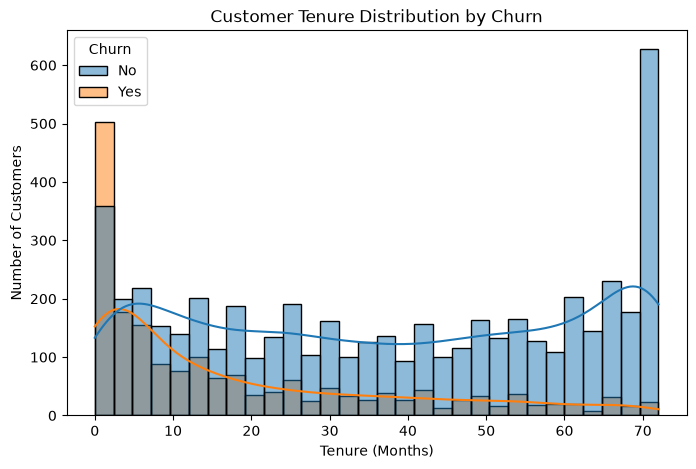

In [28]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=30,
    kde=True
)

plt.title('Customer Tenure Distribution by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

In [29]:
bins = [0, 12, 24, 48, 72]

labels = ['0-12 Months', '13-24 Months',
          '25-48 Months', '49-72 Months']

df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [30]:
pd.crosstab(
    df['TenureGroup'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
TenureGroup,,
0-12 Months,52.561757,47.438243
13-24 Months,71.289062,28.710938
25-48 Months,79.611041,20.388959
49-72 Months,90.486824,9.513176


In [31]:
df.groupby('Churn')['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


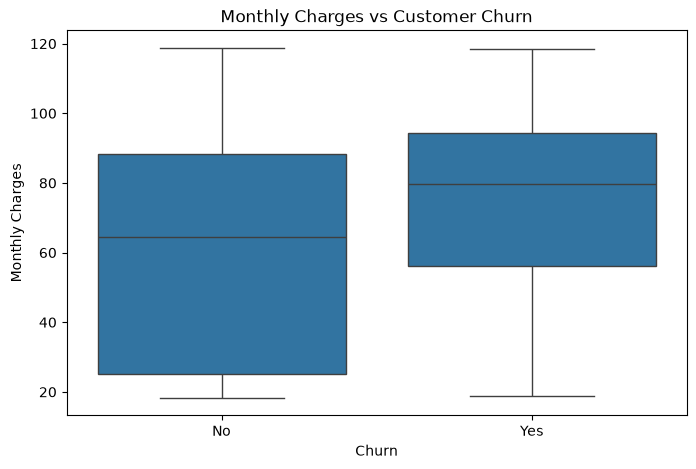

In [32]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()

In [33]:
df.groupby('Churn')['TotalCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,2549.911442,2329.954215,0.00,572.9,1679.525,4262.85,8672.45
Yes,1869.0,1531.796094,1890.822994,18.85,134.5,703.550,2331.30,8684.80


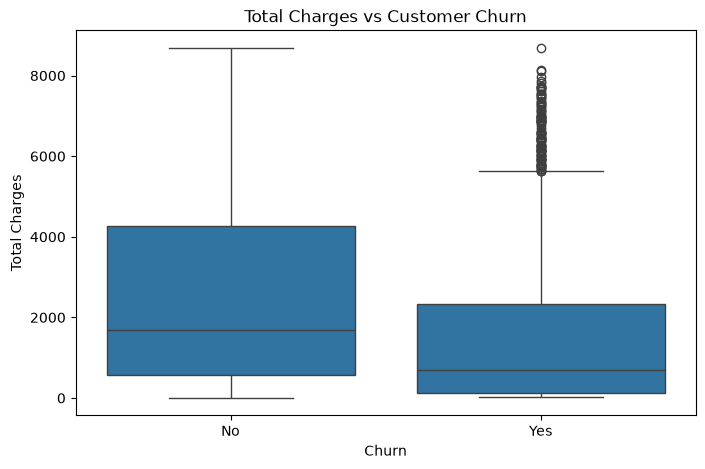

In [34]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='Churn',
    y='TotalCharges'
)

plt.title('Total Charges vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Total Charges')

plt.show()

In [35]:
pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


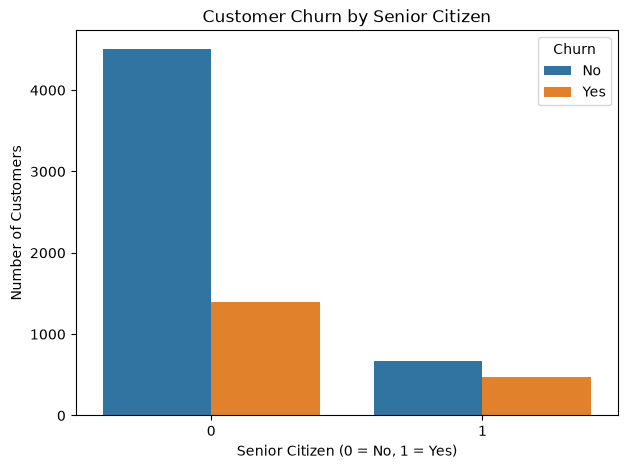

In [36]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='SeniorCitizen',
    hue='Churn'
)

plt.title('Customer Churn by Senior Citizen')
plt.xlabel('Senior Citizen (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

plt.show()

In [37]:
pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


In [38]:
pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


In [39]:
pd.crosstab(
    df['PaperlessBilling'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


In [40]:
pd.crosstab(
    df['PhoneService'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
PhoneService,,
No,75.073314,24.926686
Yes,73.290363,26.709637


In [41]:
pd.crosstab(
    df['OnlineSecurity'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


In [42]:
pd.crosstab(
    df['TechSupport'],
    df['Churn'],
    normalize='index'
) * 100


Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


In [43]:
pd.crosstab(
    df['OnlineBackup'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
OnlineBackup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


In [44]:
pd.crosstab(
    df['DeviceProtection'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
DeviceProtection,,
No,60.872375,39.127625
No internet service,92.595020,7.404980
Yes,77.497936,22.502064


In [45]:
pd.crosstab(
    df['StreamingTV'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
StreamingTV,,
No,66.476868,33.523132
No internet service,92.595020,7.404980
Yes,69.929812,30.070188


In [46]:
pd.crosstab(
    df['StreamingMovies'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
StreamingMovies,,
No,66.319569,33.680431
No internet service,92.595020,7.404980
Yes,70.058565,29.941435


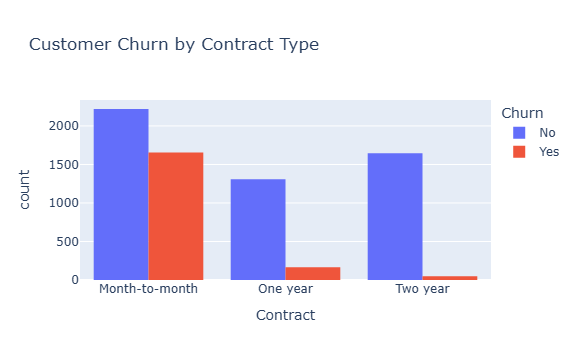

In [47]:
fig = px.histogram(
    df,
    x='Contract',
    color='Churn',
    barmode='group',
    title='Customer Churn by Contract Type'
)

fig.show()

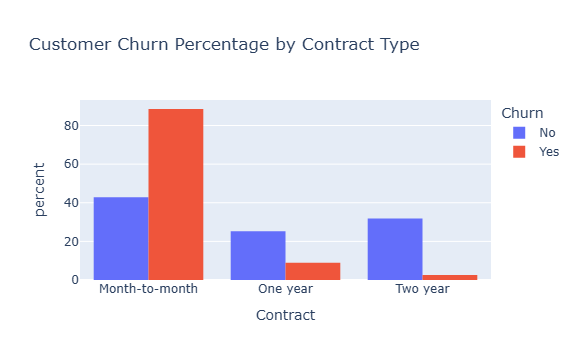

In [48]:
fig = px.histogram(
    df,
    x='Contract',
    color='Churn',
    barmode='group',
    histnorm='percent',
    title='Customer Churn Percentage by Contract Type'
)

fig.show()

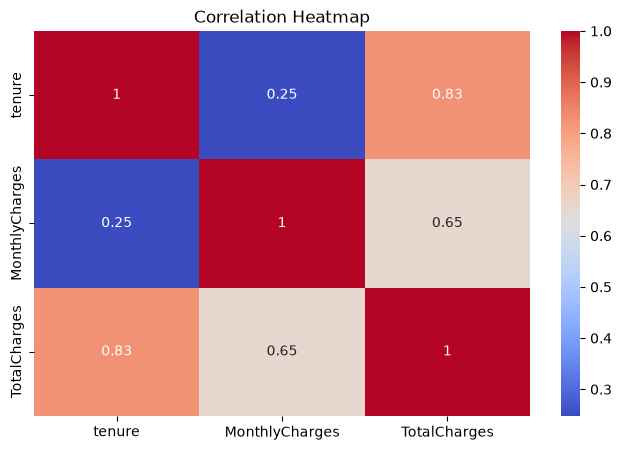

In [49]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

## Exploratory Data Analysis (EDA) – Key Findings

### 1. Dataset Overview
- Total customers: 7,043
- Total features: 21
- Churned customers: 1,869 (26.54%)
- Non-churned customers: 5,174 (73.46%)

### 2. Customer Churn Insights
- Month-to-month contract customers have the highest churn rate (42.71%).
- One-year contract customers have a churn rate of 11.27%.
- Two-year contract customers have the lowest churn rate (2.83%).
- Customers with shorter tenure show a higher churn rate.
- Electronic check users have a higher churn rate (45.29%).
- Customers without Online Security and Tech Support have higher churn rates.

### 3. Numerical Feature Insights
- Churned customers have higher average MonthlyCharges.
- Churned customers have lower average TotalCharges.
- Tenure and TotalCharges have a strong positive correlation (0.83).
- MonthlyCharges and TotalCharges have a moderate positive correlation (0.65).

### 4. Conclusion
The analysis indicates that contract type, tenure, payment method, and additional internet services are associated with customer churn. These findings will help guide the next stage of machine learning analysis.

## Final Visualizations

## Customer Churn Distribution

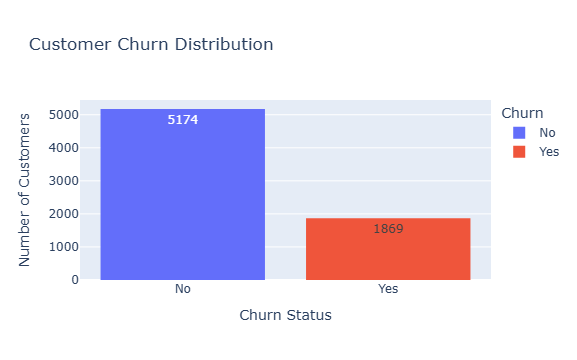

In [50]:
fig = px.histogram(
    df,
    x='Churn',
    color='Churn',
    title='Customer Churn Distribution',
    text_auto=True,
    color_discrete_map={
        'No': '#636EFA',
        'Yes': '#EF553B'
    }
)

fig.update_layout(
    xaxis_title='Churn Status',
    yaxis_title='Number of Customers'
)

fig.show()

## **Observation:**

The dataset shows that 73.46% of customers stayed with the company, while 26.54% discontinued the service. This indicates that approximately one out of every four customers churned.

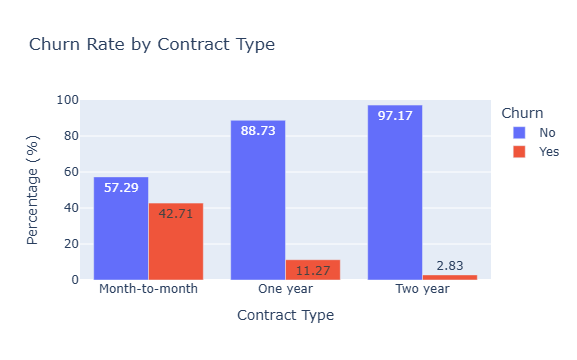

In [51]:

contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

contract_churn = contract_churn.reset_index().melt(
    id_vars='Contract',
    var_name='Churn',
    value_name='Percentage'
)

fig = px.bar(
    contract_churn,
    x='Contract',
    y='Percentage',
    color='Churn',
    barmode='group',
    title='Churn Rate by Contract Type',
    color_discrete_map={
        'No': '#636EFA',
        'Yes': '#EF553B'
    },
    text_auto='.2f'
)

fig.update_layout(
    xaxis_title='Contract Type',
    yaxis_title='Percentage (%)',
    yaxis=dict(range=[0, 100])
)

fig.show()


## **Observation:**

Month-to-month contract customers have the highest churn rate (42.71%), while two-year contract customers have the lowest churn rate (2.83%). This suggests that customers with long-term contracts are less likely to leave the service.

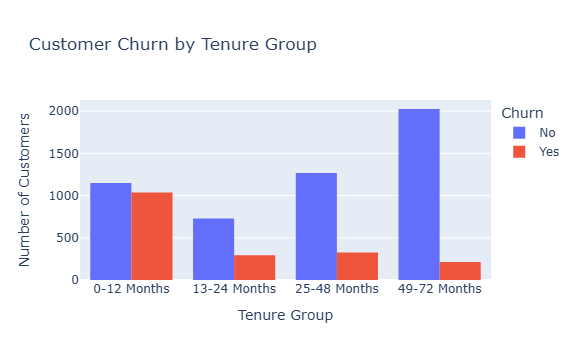

In [52]:
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[0, 12, 24, 48, 72],
    labels=['0-12 Months', '13-24 Months',
            '25-48 Months', '49-72 Months'],
    include_lowest=True
)
fig = px.histogram(
    df,
    x='TenureGroup',
    color='Churn',
    barmode='group',
    title='Customer Churn by Tenure Group',
    category_orders={
        'TenureGroup': [
            '0-12 Months',
            '13-24 Months',
            '25-48 Months',
            '49-72 Months'
        ]
    },
    color_discrete_map={
        'No': '#636EFA',
        'Yes': '#EF553B'
    }
)

fig.update_layout(
    xaxis_title='Tenure Group',
    yaxis_title='Number of Customers'
)

fig.show()

## **Observation:**

Customers with shorter tenure have a higher churn rate. The 0–12 months group has the highest churn rate (47.44%), while the 49–72 months group has the lowest churn rate (9.51%). This suggests that customer retention is particularly important during the early months of service.

## # Business Insights & Recommendations

## Key Business Insights

1. Month-to-month contract customers have the highest churn rate (42.71%).
2. Customers with 0–12 months of tenure have the highest churn rate (47.44%).
3. Electronic Check users have a higher churn rate (45.29%).
4. Fiber Optic users show a higher churn rate (41.89%).
5. Customers without Tech Support have a higher churn rate (41.64%).

## Business Recommendations

1. **Improve Early Customer Retention:** Provide better onboarding and customer support during the first 12 months.
2. **Encourage Long-term Contracts:** Offer attractive incentives for customers choosing long-term contracts.
3. **Review Payment Experience:** Investigate potential issues affecting Electronic Check users.
4. **Improve Fiber Optic Service:** Evaluate service quality and customer satisfaction among Fiber Optic users.
5. **Promote Technical Support:** Make technical support more accessible to customers.

## Business Conclusion

The analysis suggests that contract type, customer tenure, payment method, internet service, and technical support are associated with customer churn. These findings can help the company develop targeted customer retention strategies.

## # Final EDA Conclusion

The Exploratory Data Analysis of the Telco Customer Churn dataset revealed several important patterns related to customer retention.

### Key Findings
- Approximately 26.54% of customers discontinued the service.
- Month-to-month contract customers showed a higher churn rate.
- Customers with shorter tenure were more likely to churn.
- Electronic Check users had a higher churn rate.
- Customers without Online Security and Tech Support showed higher churn rates.
- Tenure and TotalCharges had a strong positive correlation (0.83).

### Conclusion
EDA helped identify important patterns and relationships in customer behavior. These findings provide a foundation for further analysis and machine learning.

### Next Step
The next phase will focus on data preprocessing, feature engineering, model building, and evaluation to predict customer churn.

In [53]:
import os
print(os.getcwd())

C:\Users\Hp


In [ ]:
from pathlib import Path

files = list(Path.home().rglob("01_Telco_Data_Analysis.ipynb"))

for file in files:
    print(file)